# Multi-planet Fits #

by Jason Wang (2020)

In `orbitize!`, we can fit for multiple planets in the system in the same way as fitting a single planet. Note that currently, `orbitize!` handles planet-planet gravitational interations with an nbody integrator solver. However, here, we only take into account star-planet interactions. For example, the distance between planet b and the star will change with the existance of planet c because planet c has some finite mass and perturbs the star from the system barycenter. Even without planet-planet scattering, one can approximately fit for dynamical masses this way. By default in `orbitize!`, we assume the planets are test particles (mass = 0), so there is no star-planet interactions. Later in this tutorial in the "Multiplanet Dynamical Mass" section, we will describe how to turn on this feature. 

Multi-planet capabilities are generally handled under the hood, requiring not many modifications to the procedure for fitting a single planet. In this example, we will fit a few measurements of the HR 8799 b and c planets.


In [1]:
import os

import orbitize
import orbitize.driver
import orbitize.plot

In this tutorial, we will do an example with OFTI just because it is fast. However, in most cases, you will likely want to use MCMC as OFTI slows down significantly with multiple planets (even if each planet only has two astrometric data points as shown in the example). MCMC also requires longer run time typically, but it generally scales better than OFTI.

We follow the same steps as in the [OFTI tutorial](https://orbitize.readthedocs.io/en/latest/tutorials/OFTI_tutorial.html) but set number of secondary bodies to 2 and read in a data file that contains astrometry for two planets in the system (in the example, a shortened version of the HR 8799 b and c astrometry). For MCMC, do the same thing as the single planet [MCMC tutorial](https://orbitize.readthedocs.io/en/latest/tutorials/MCMC_tutorial.html) and make the same challenges as we have here with OFTI. In summary, all that needs to be done is to include both planets' measurements in the input data file and adjust the number of secondary bodies in the system. 


In [2]:
input_file = os.path.join(orbitize.DATADIR, "test_val_multi.csv")
myDriver = orbitize.driver.Driver(
    input_file,
    "OFTI",
    2,  # number of secondary bodies in system
    1.52,  # total mass [M_sun]
    24.76,  # total parallax of system [mas]
    mass_err=0.15,
    plx_err=0.64,
)

Converting ra/dec data points in data_table to sep/pa. Original data are stored in input_table.


/Users/bluez3303/Documents/GitHub/orbitize/orbitize/sampler.py:413: UserWarning: OFTI is depracated. Please use MCMC with OFTeI marginalization for faster and more accurate results.
  warnings.warn(


Next we run the sampler as usual:

In [3]:
s = myDriver.sampler
orbits = s.run_sampler(1000)

With two planets, we have 2 sets of 6 orbtial parameters as well as the 2 system parameters (parallax and total mass). Our posterior, stored in `orbits`, is a (1000 x 14) array instead of the (1000 x 8) array had we fit a single planet. 

As it gets confusing to track with index corresponds to which orbital parameter, we recommend you use the system.param_idx to index the parameters you are interested in. As a reminder, the abbreviations are: semi-major axis (sma), eccentricity (ecc), inclination (inc), argument of periastron (aop), position angle of nodes (pan), and epoch of periastron passage in fraction of the orbital period (tau). The 1 and 2 correspond to the two secondary bodies (in this case, HR 8799 b and HR 8799 c respectively)

In [4]:
print(orbits[0])
print(orbits.shape)
print(s.system.param_idx)

[9.09586066e+01 6.57768266e-02 6.72285142e-01 4.77120790e+00
 2.72309664e+00 1.79600025e-03 3.10376588e+01 2.21909866e-01
 7.11579664e-01 2.68426432e+00 5.86534697e+00 4.12708967e-01
 2.58070150e+01 1.27515866e+00]
(1000, 14)
{'sma1': np.int64(0), 'ecc1': np.int64(1), 'inc1': np.int64(2), 'aop1': np.int64(3), 'pan1': np.int64(4), 'tau1': np.int64(5), 'sma2': np.int64(6), 'ecc2': np.int64(7), 'inc2': np.int64(8), 'aop2': np.int64(9), 'pan2': np.int64(10), 'tau2': np.int64(11), 'plx': np.int64(12), 'mtot': np.int64(13)}


## Plotting ##

We will go over briefly some considerations for visualizing multiplanet fits using the `orbitize!` API. For a more detailed guide on data visualization capabilities within orbitize, see the [Orbitize plotting tutorial](https://orbitize.info/en/latest/tutorials/Plotting_tutorial.html).

### Corner Plot ###

Corner plots are slow when trying to plot too many parameters (the number of subplots scales as n^2 where n is the number of dimensions). It also is difficult to read a plot with too many subplots. For this reason, we recommend looking at particular parameter covariances, or breaking it up to have one corner plot for each planet. Again, use the notation in `system.param_idx` notation to grab the parameters you want.

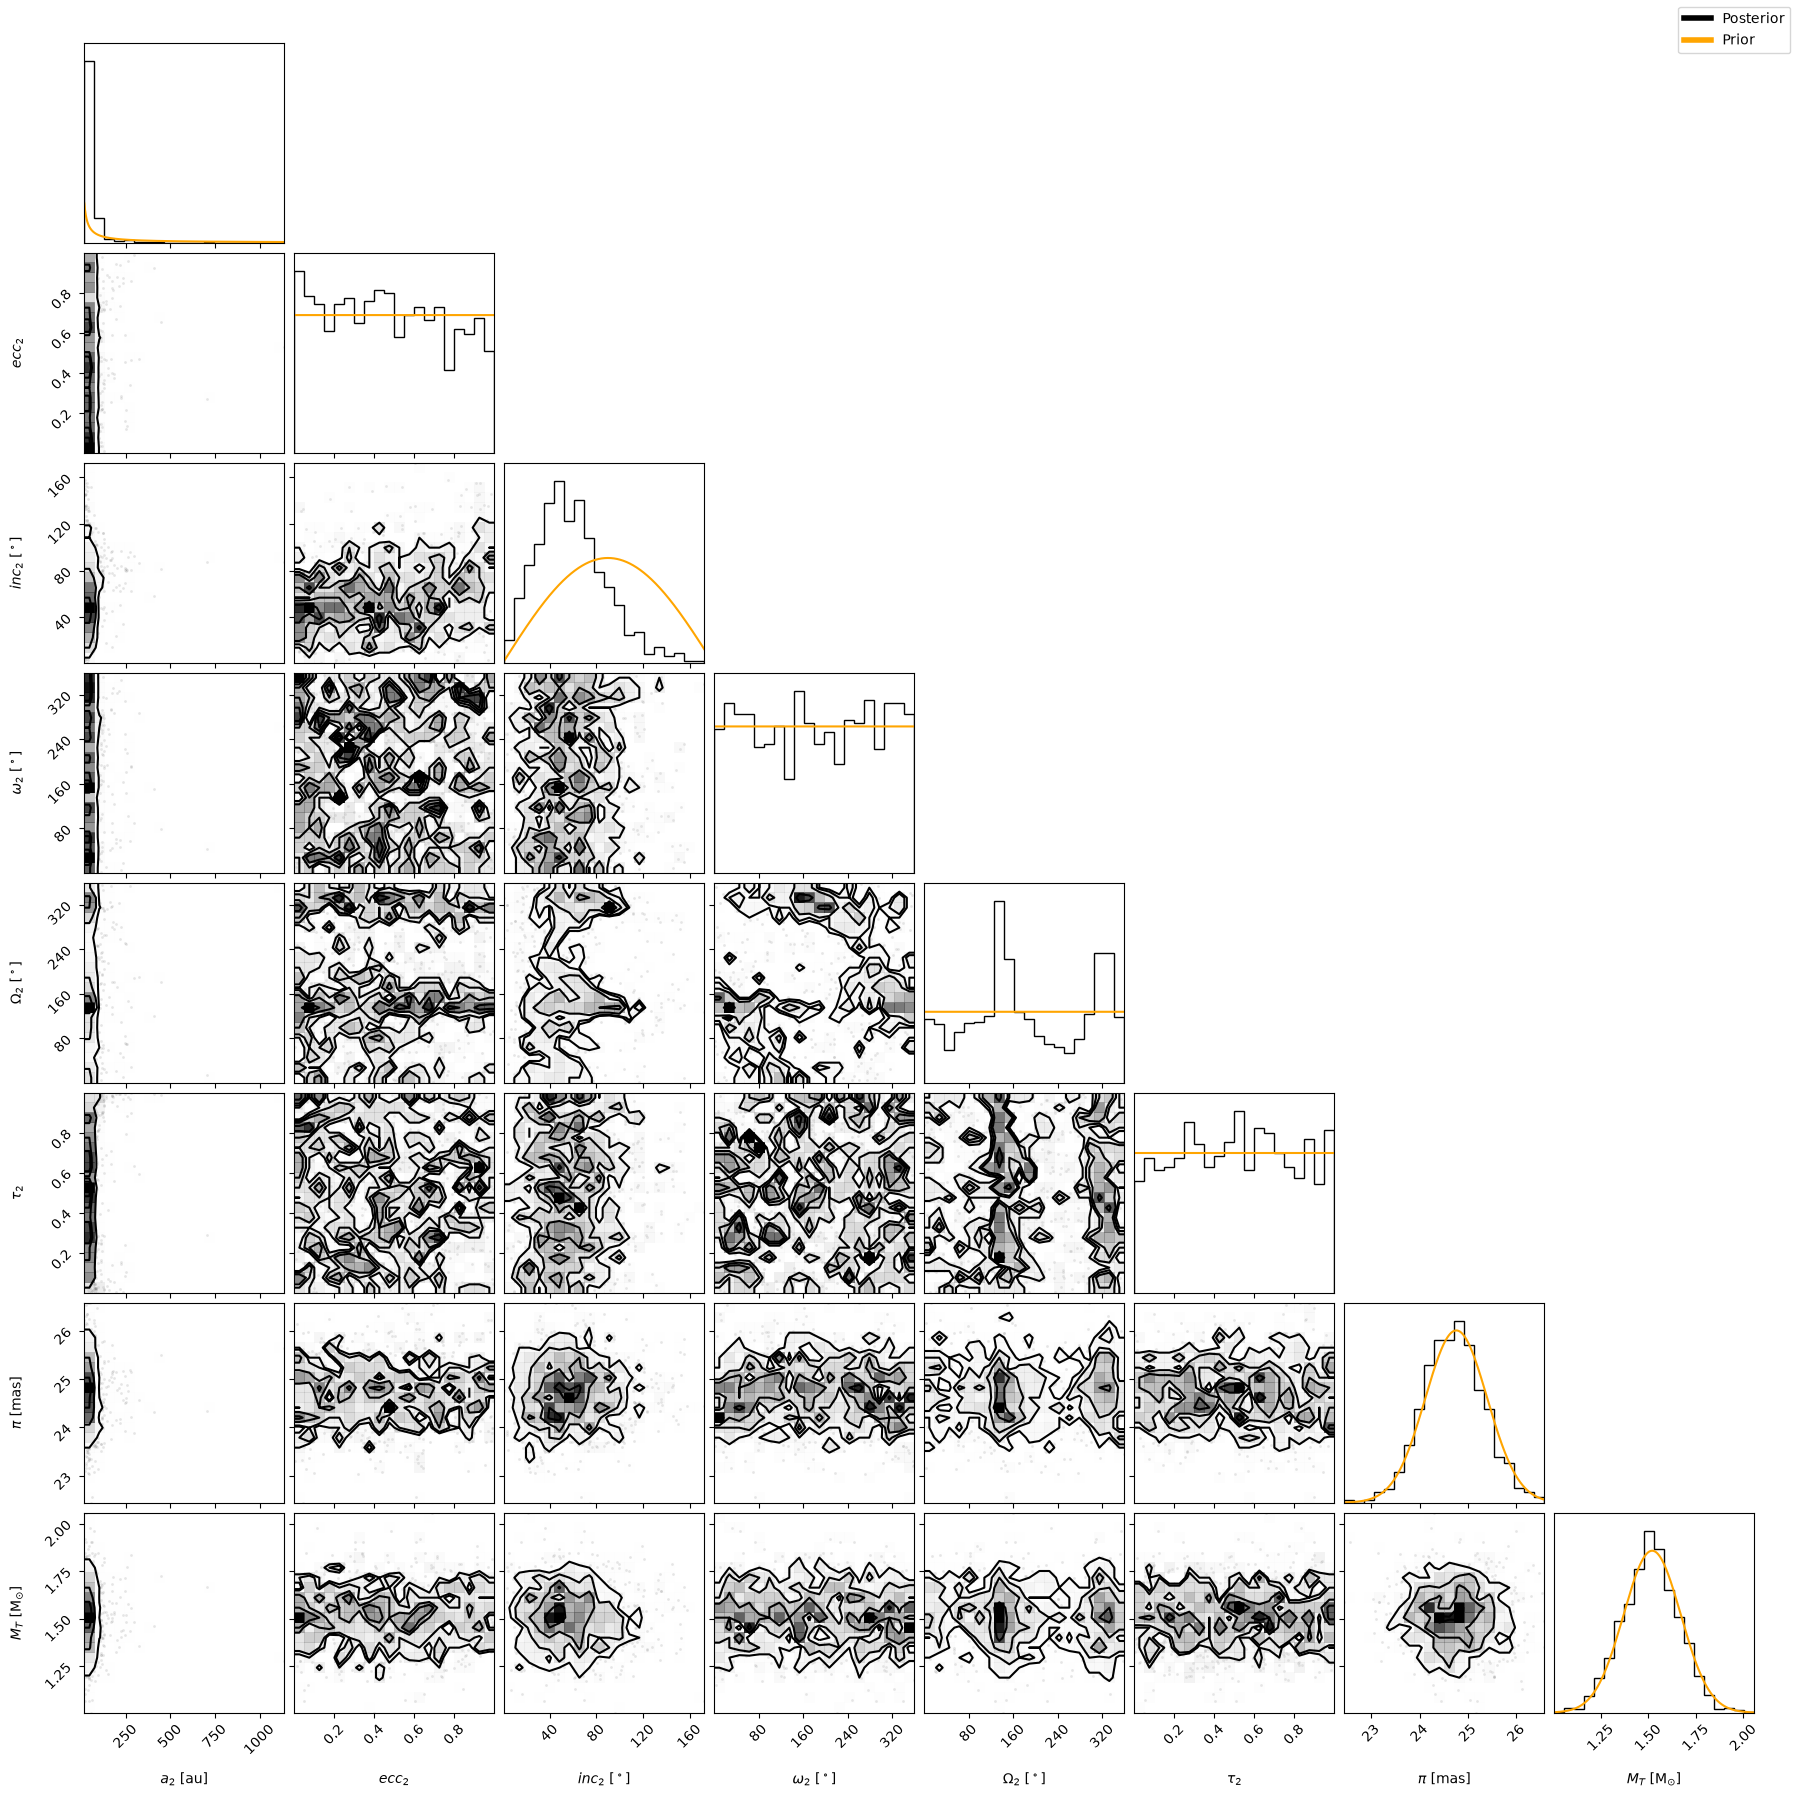

In [5]:
myResults = s.results
corner_figure = orbitize.plot.plot_corner(
    myResults,
    param_list=["sma2", "ecc2", "inc2", "aop2", "pan2", "tau2", "plx", "mtot"],
)

### Orbit Plot ###

You can plot different objects using the `object_to_plot` keyword which can be either the integer index of a single object to plot or a list of those integers.

/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


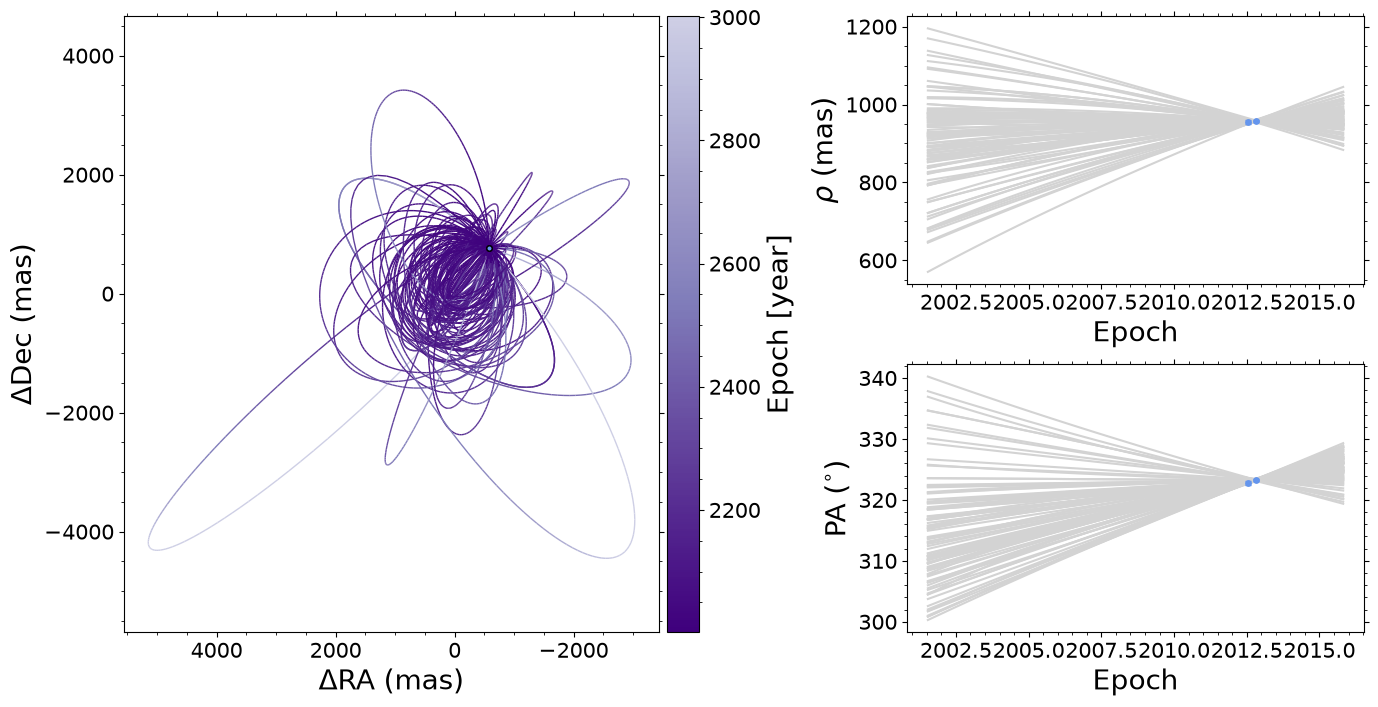

In [6]:
myPlotter = orbitize.plot.Plotter(
    myResults,
    object_to_plot=2,  # plot planet c
)
orbit_figure = myPlotter.plot_orbits()

/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


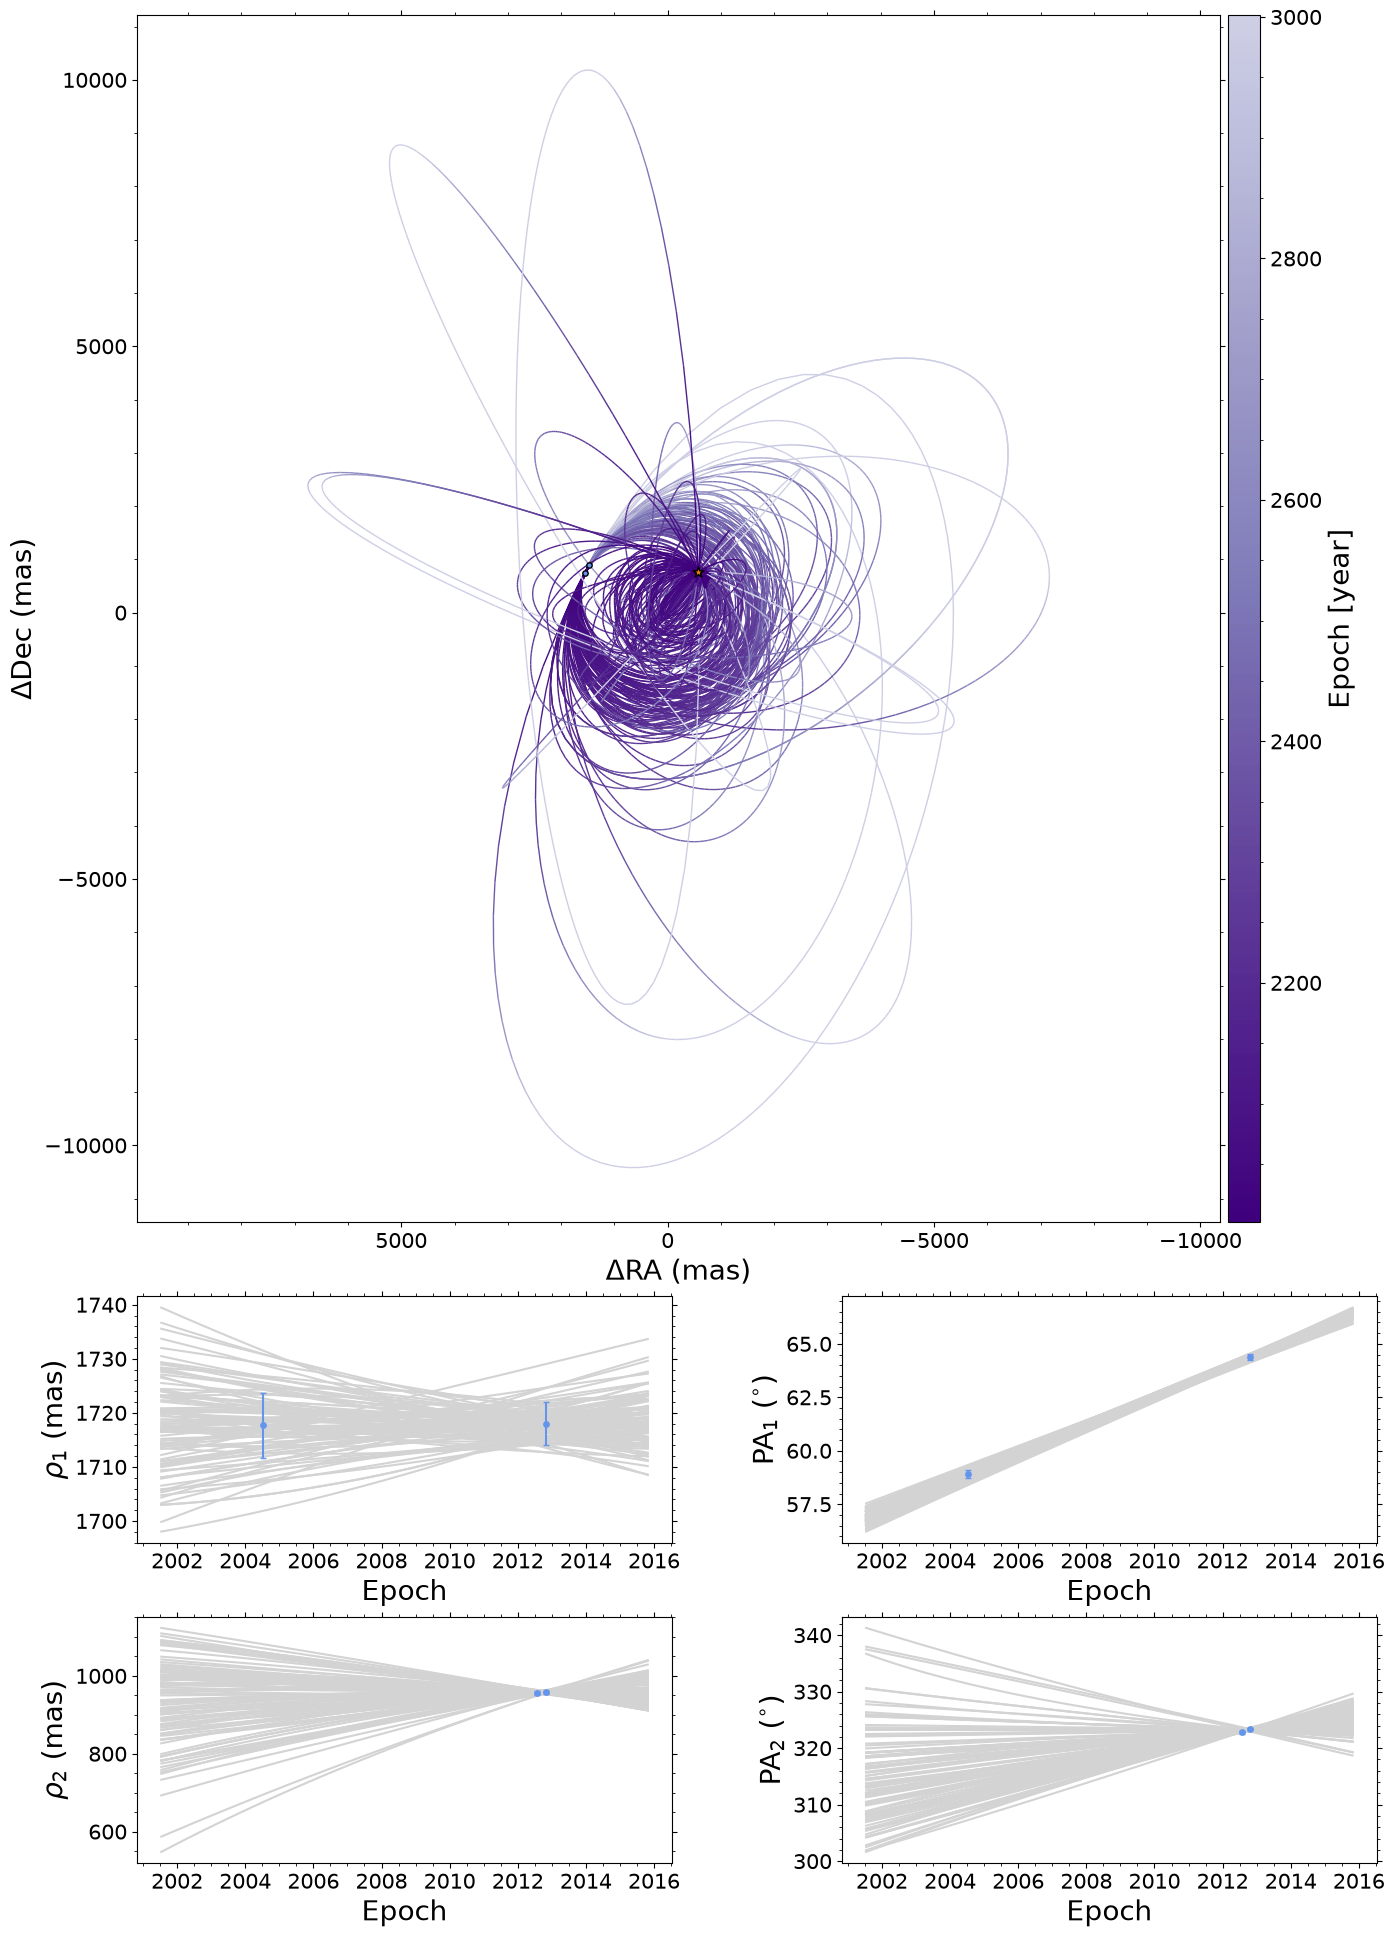

In [7]:
myPlotter.set_params(
    object_to_plot=[1, 2]  # plot planet b and c
)
orbit_figure_multi = myPlotter.plot_orbits()

Instead of labeling each object as a subscript in the axis labels by their indexes, you can set custom labels using the `OBJECT_LABELS` variable.

/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


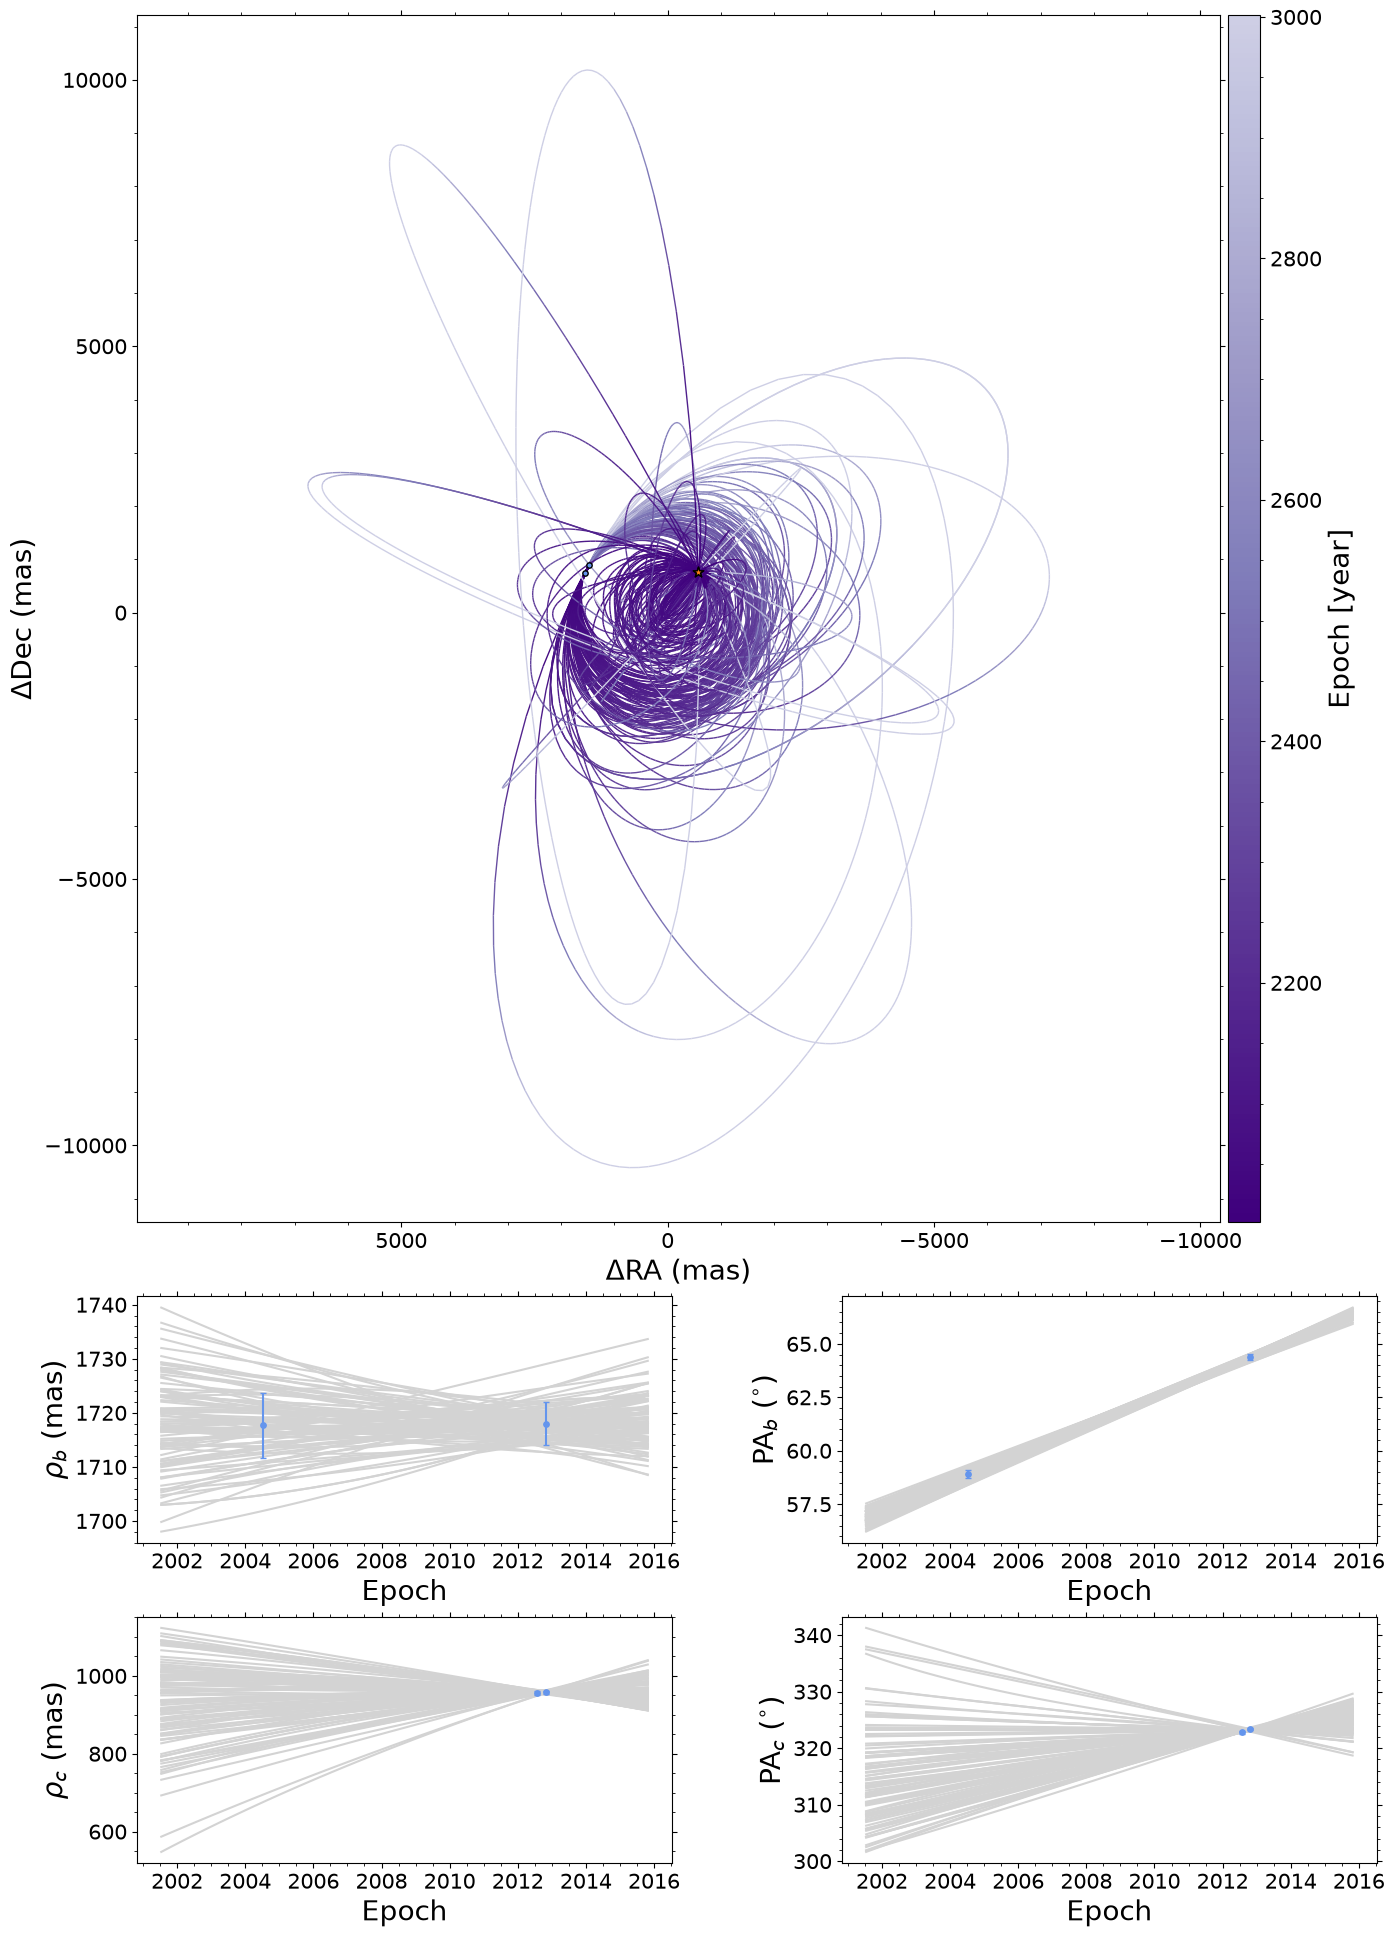

In [8]:
myPlotter.OBJECT_LABELS[1] = "b"
myPlotter.OBJECT_LABELS[2] = "c"
orbit_figure_labels = myPlotter.plot_orbits()

It may be hard to differentiate between the objects being plotted. Setting `use_cmap=False` colors each object with a single color according to the `MODEL_COLORS` variable. See the [Advanced Plotting Tutorial](https://orbitize.readthedocs.io/en/latest/tutorials/Plotting_tutorial.html) for more information.

/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


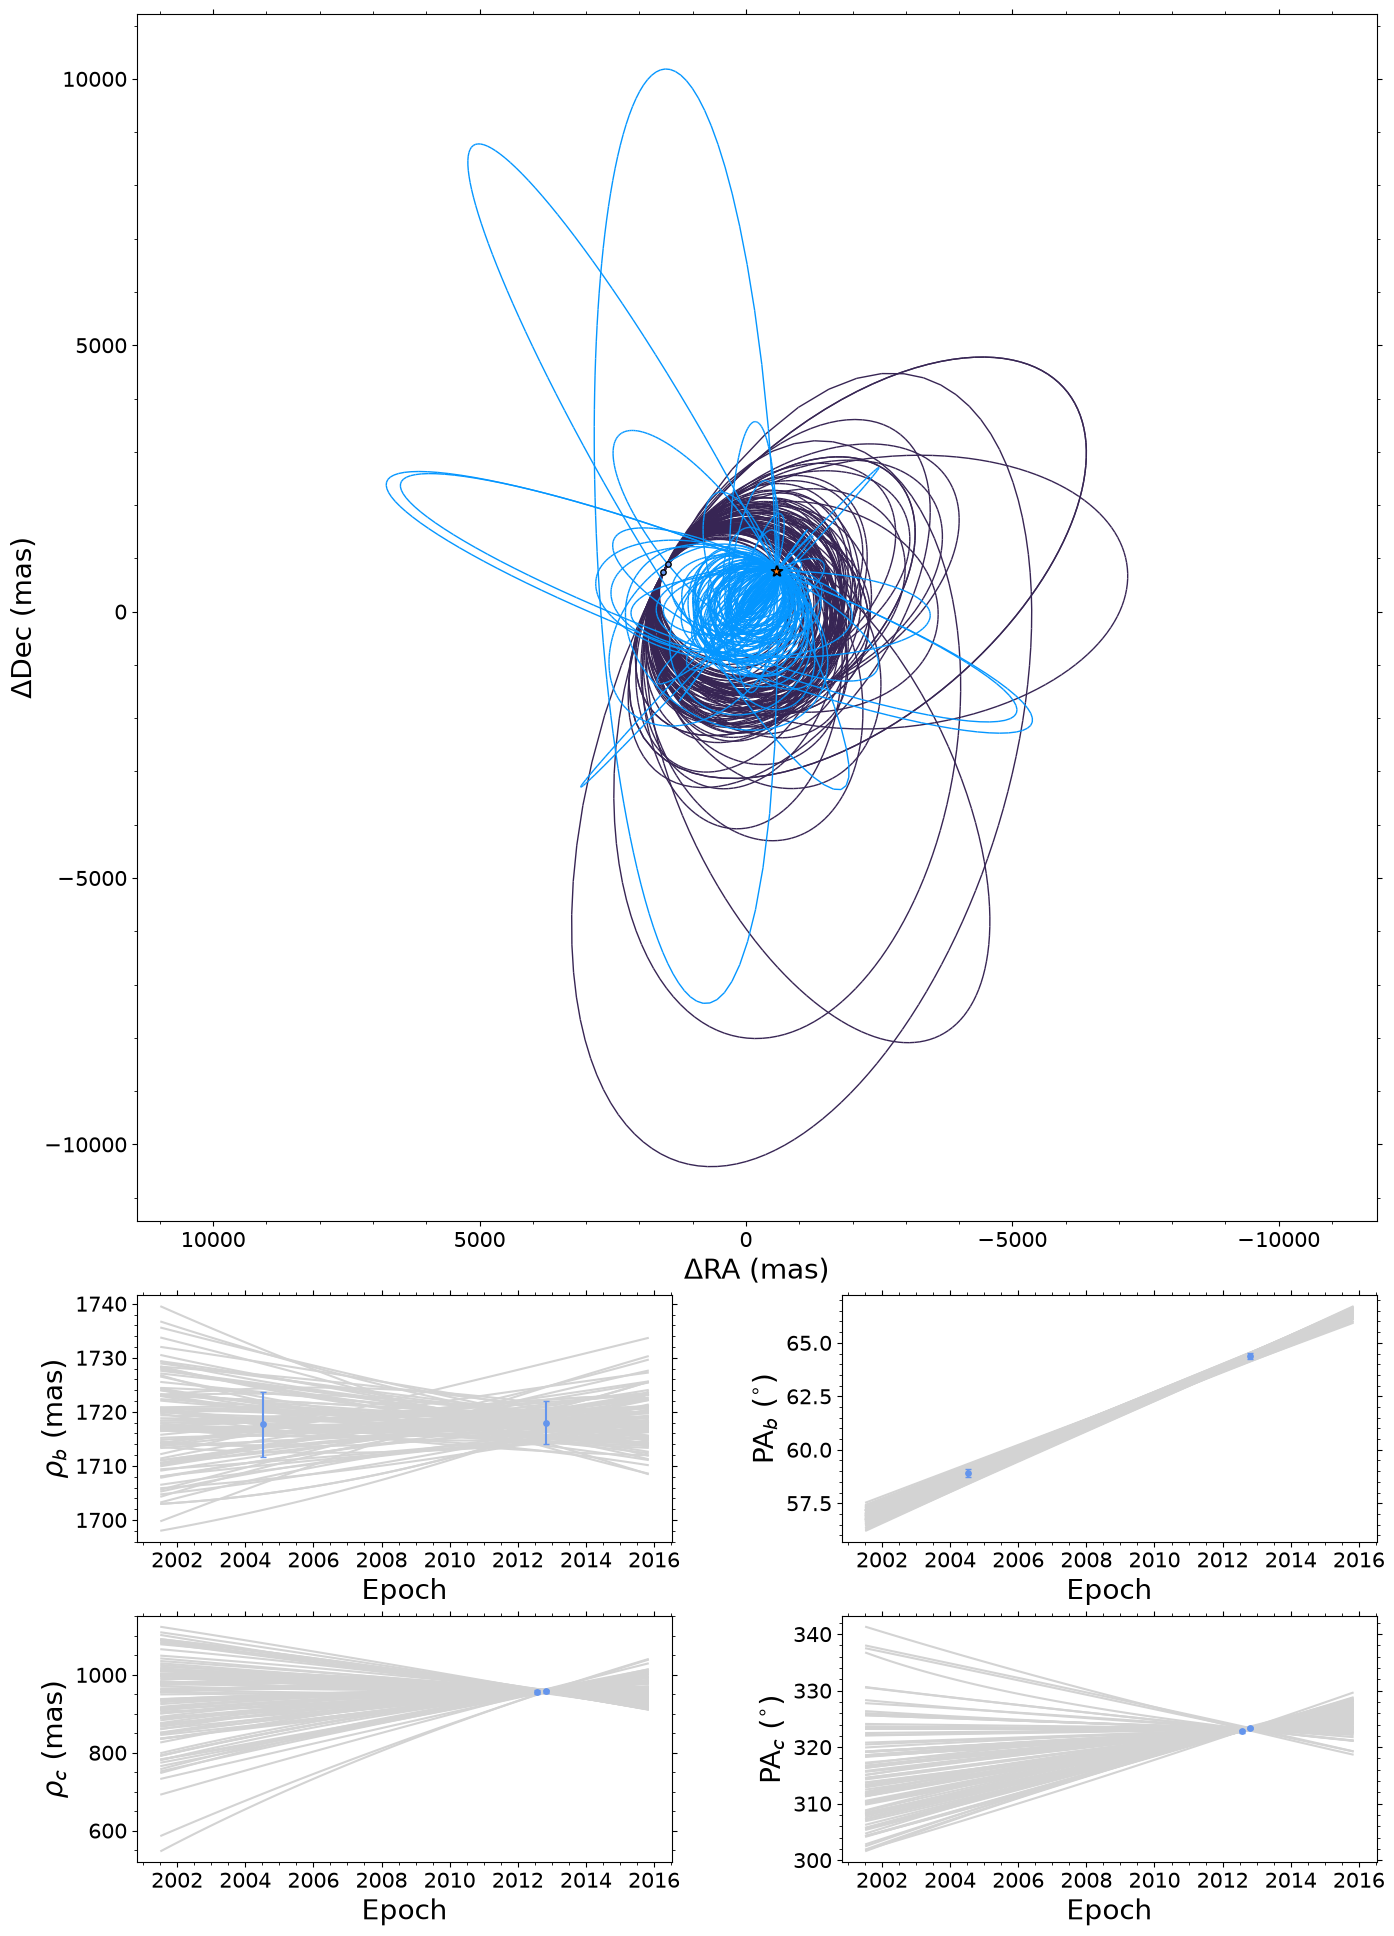

In [9]:
orbit_figure_no_cmap = myPlotter.plot_orbits(use_cmap=False)

Alternatively, setting the `cmap` keyword or `CMAP` variable to a list of colormaps rather than a single one will cause each object to be plotted using a different colormap on the same scale. 

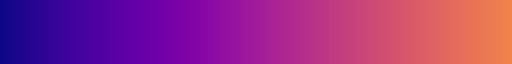

In [10]:
import matplotlib as mpl
import numpy as np

mpl_new_cmap = mpl.cm.plasma
new_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    f"trunc({mpl_new_cmap.name},{0.0:.2f},{0.7:.2f})",
    mpl_new_cmap(np.linspace(0.0, 0.7, 1000)),
)
new_cmap

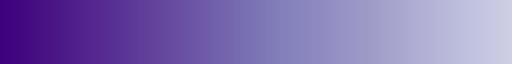

In [11]:
orbitize_cmap = myPlotter.CMAP
orbitize_cmap

/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


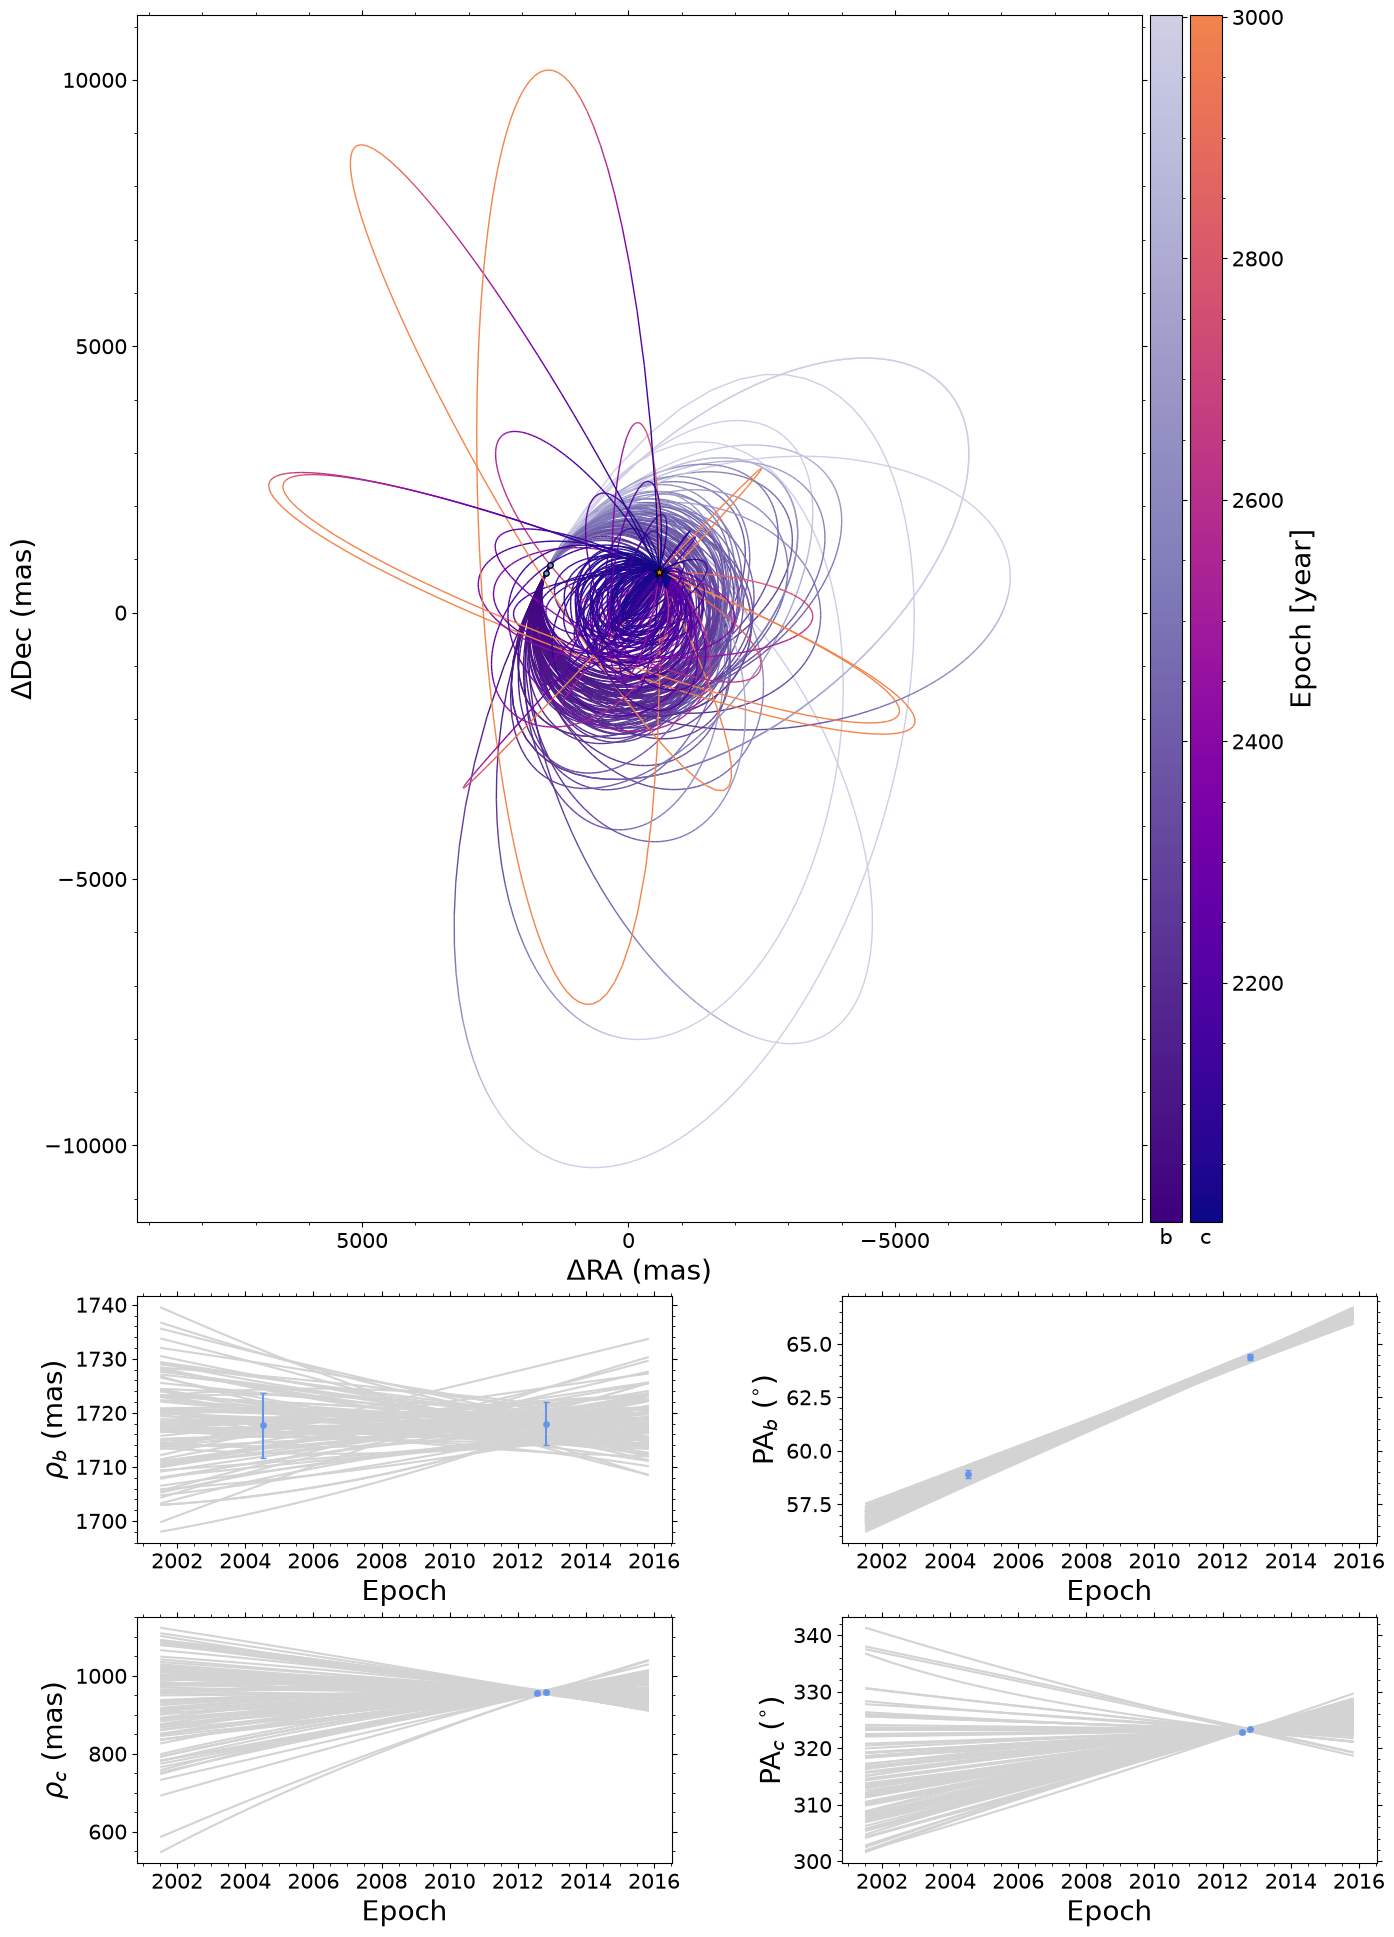

In [12]:
orbit_figure_multi_cmap = myPlotter.plot_orbits(cmap=[orbitize_cmap, new_cmap])
# Alternatively to change the default:
# myPlotter.CMAP = [orbitize_cmap, new_cmap]
# myPlotter.plot_orbits()

### Residuals Plot ###
When using `Plotter.plot_residuals`, residual plots will be created for each object in `object_to_plot`.

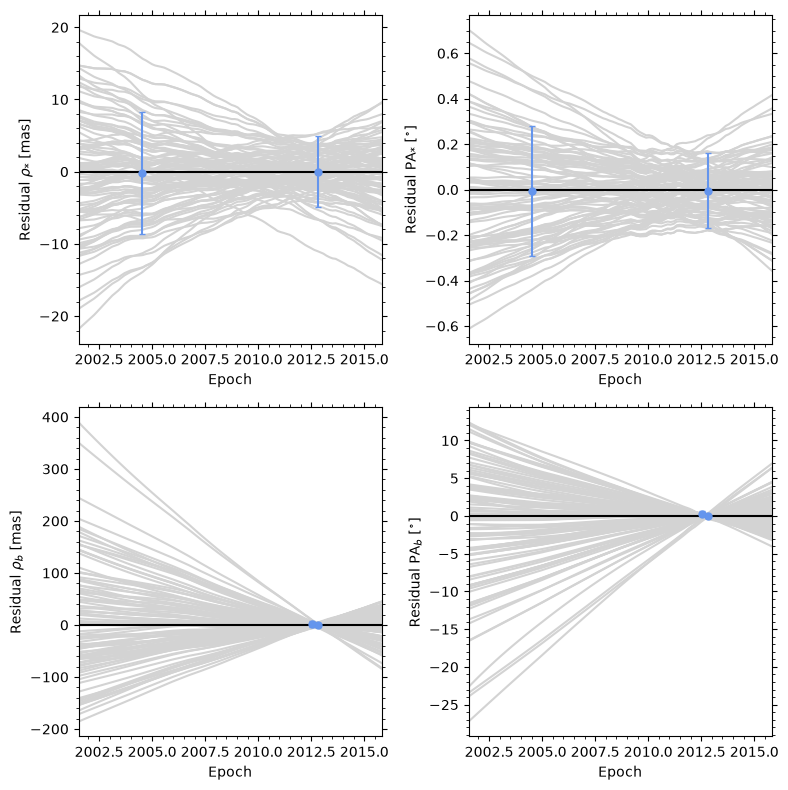

In [13]:
residuals_figure = myPlotter.plot_residuals()

## Multiplanet Dynamical Mass ##

In the case we want to fit dynamical masses, the procedure again remains unchanged as for a single planet system (as described in the [RV MCMC Tutorial](RV_MCMC_Tutorial.html)). The only thing to be aware of the extra parameters for the indiviudal masses of the components. Again, use the `system.param_idx` dictionary to keep track of the indices instead of trying to keep track of the ordering in one's head. Here, we will not demo a fit, but just show the increasing of parameters by 2 when fitting for the masses of the two secondary bodies.

Here, the new parameters are `m1` and `m2`, the masses of planets b and c. `m0` remains the mass of the star.

In [14]:
input_file2 = os.path.join(orbitize.DATADIR, "test_val_multi.csv")
myDriver2 = orbitize.driver.Driver(
    input_file2,
    "MCMC",
    2,  # number of secondary bodies in system
    1.52,  # stellar mass [M_sun]
    24.76,  # total parallax of system [mas]
    mass_err=0.15,
    plx_err=0.64,
    system_kwargs={"fit_secondary_mass": True},
)
print(myDriver2.system.param_idx)
print(len(myDriver2.system.sys_priors))

{'sma1': np.int64(0), 'ecc1': np.int64(1), 'inc1': np.int64(2), 'aop1': np.int64(3), 'pan1': np.int64(4), 'tau1': np.int64(5), 'sma2': np.int64(6), 'ecc2': np.int64(7), 'inc2': np.int64(8), 'aop2': np.int64(9), 'pan2': np.int64(10), 'tau2': np.int64(11), 'plx': np.int64(12), 'm1': np.int64(13), 'm2': np.int64(14), 'm0': np.int64(15)}
16


In [15]:
s2 = myDriver2.sampler
orbits2 = s2.run_sampler(1000)

Starting Burn in

Burn in complete. Sampling posterior now.


/Users/bluez3303/Documents/GitHub/orbitize/orbitize/priors.py:563: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/bluez3303/Documents/GitHub/orbitize/orbitize/priors.py:419: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log(element_array * normalizer)



Run complete


In [16]:
myResults2 = s2.results

When fitting the secondary mass it is possible to also plot the orbit of the primary.

In [17]:
mpl_cmaps = [mpl.cm.Greens_r, mpl.cm.Reds_r, mpl.cm.Purples_r]
cmaps = [
    mpl.colors.LinearSegmentedColormap.from_list(
        f"trunc({mpl_new_cmap.name},{0.0:.2f},{0.7:.2f})",
        mpl_new_cmap(np.linspace(0.0, 0.7, 1000)),
    )
    for mpl_new_cmap in mpl_cmaps
]

In [18]:
myPlotter2 = orbitize.plot.Plotter(
    myResults2,
    object_to_plot=[0, 1, 2],
    num_orbits_to_plot=4,
)
myPlotter2.OBJECT_LABELS = {0: "*", 1: "b", 2: "c"}

/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


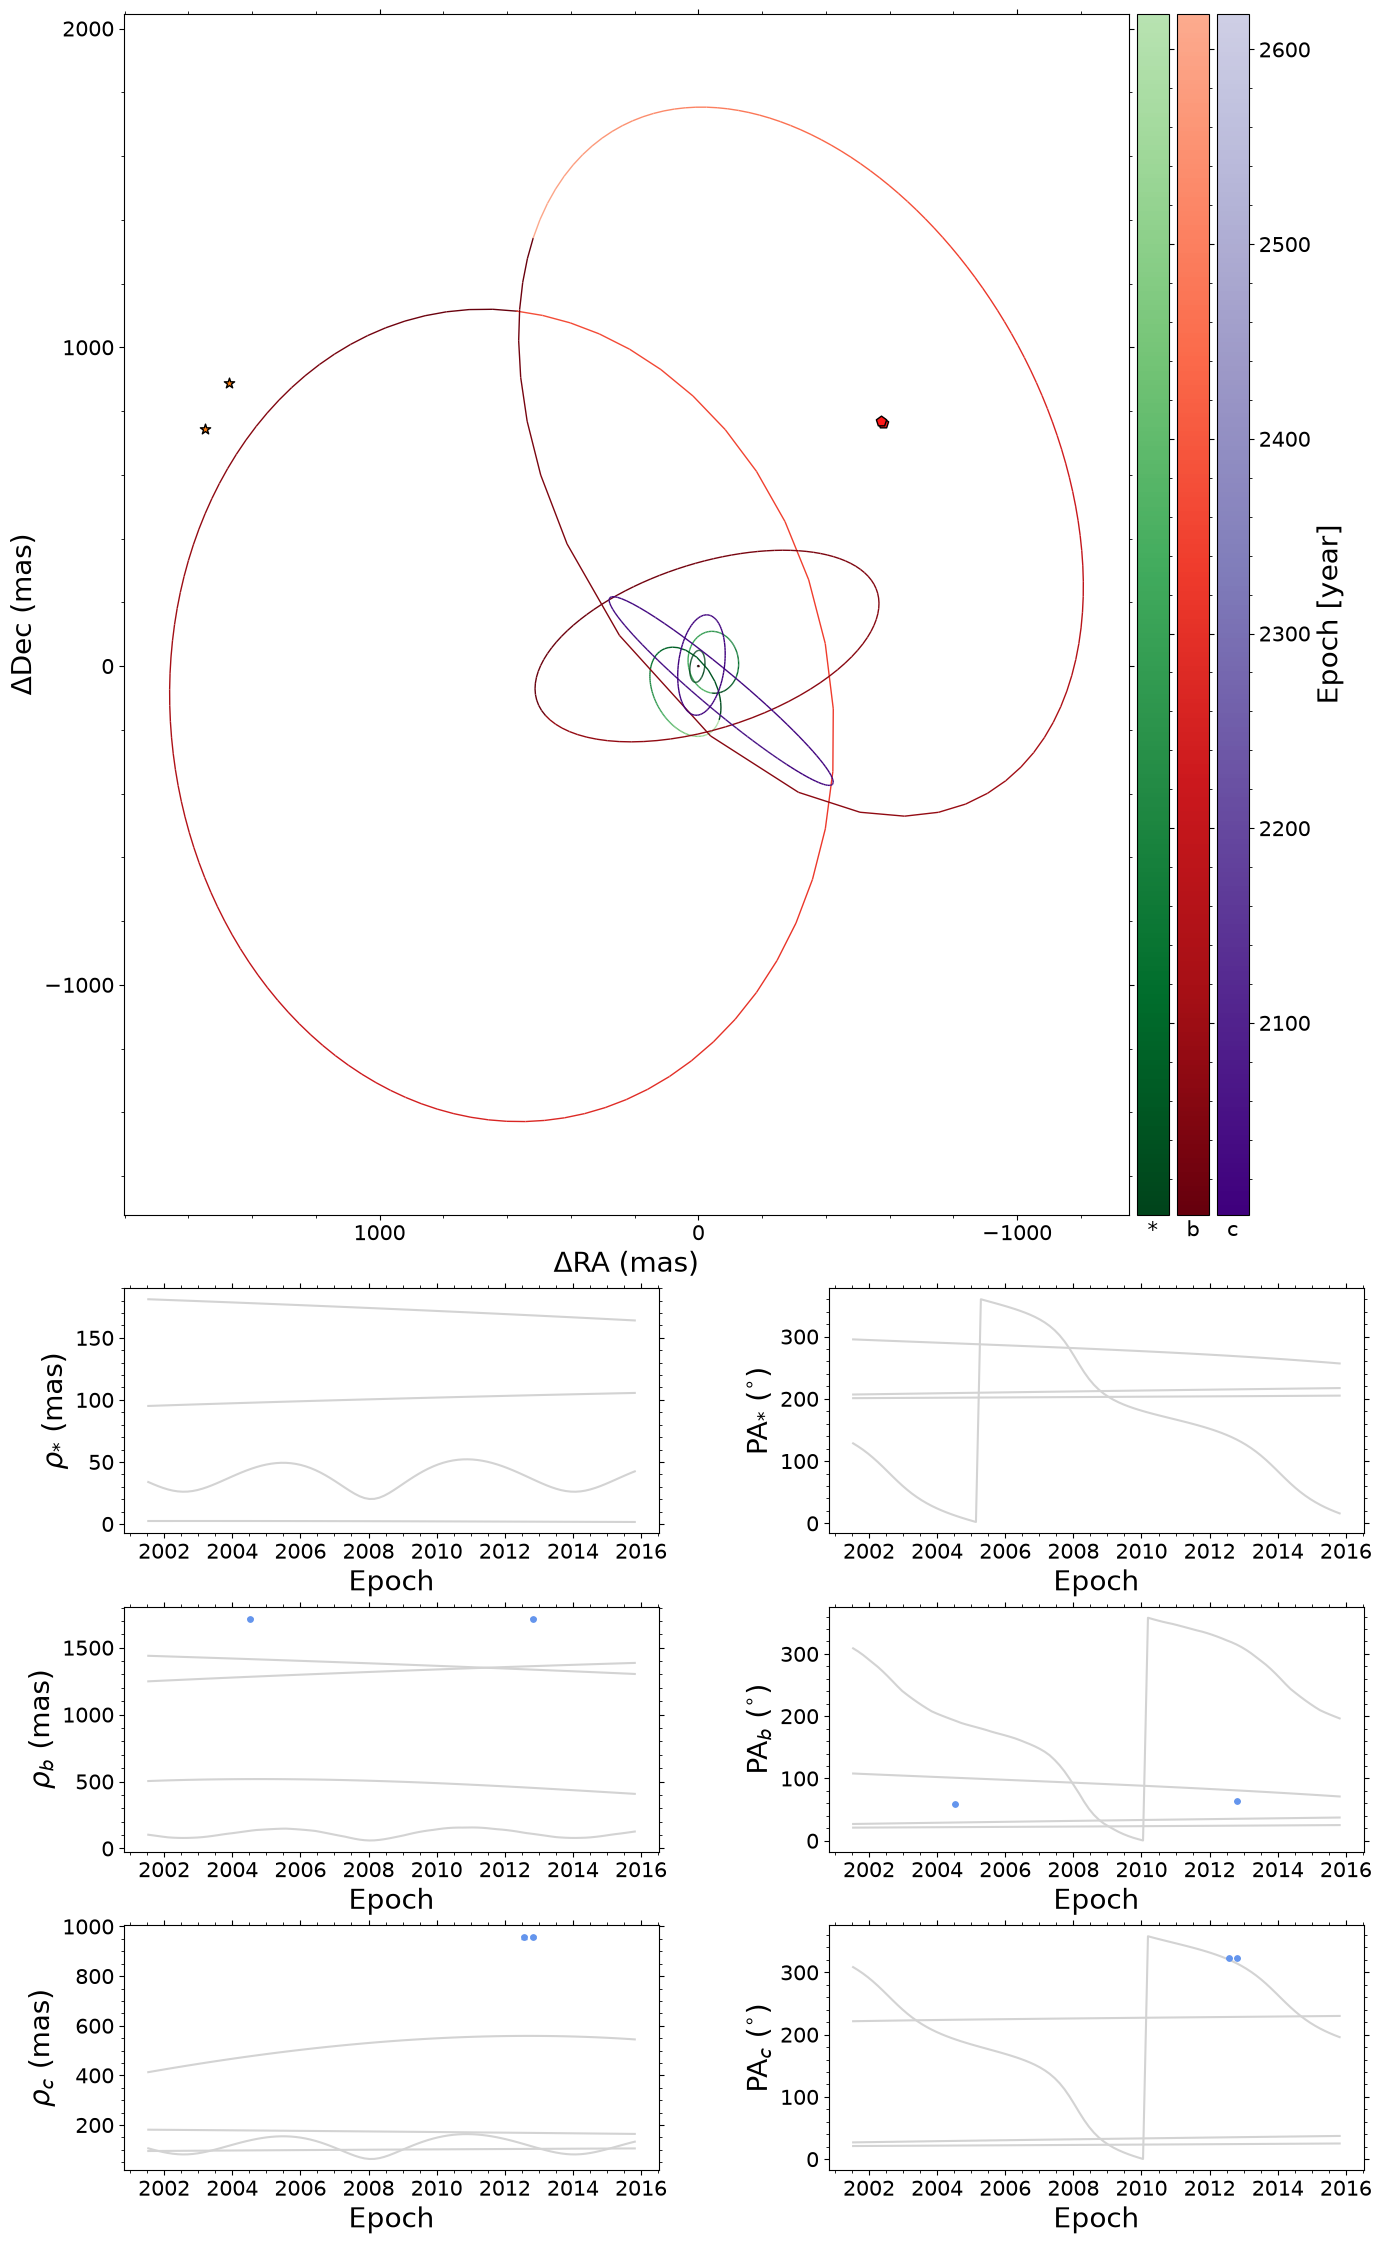

In [19]:
orbit_figure_primary = myPlotter2.plot_orbits(cmap=cmaps)

Because this plot can be messy, you may wish to plot only the best set of orbital parameters. See the [Advanced Plotting Tutorial](https://orbitize.readthedocs.io/en/latest/tutorials/Plotting_tutorial.html) for more information.

In [20]:
index_of_best_post = np.argmax(myResults2.lnlike)
best_post = myResults2.post[index_of_best_post]
standard_post = best_post.reshape((1, -1))  # Make 2d num_orbits x num_params

In [21]:
myPlotter2.set_params(num_orbits_to_plot=1, post_to_use=standard_post)

/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/bluez3303/Documents/GitHub/orbitize/orbitize/plot.py:1938: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


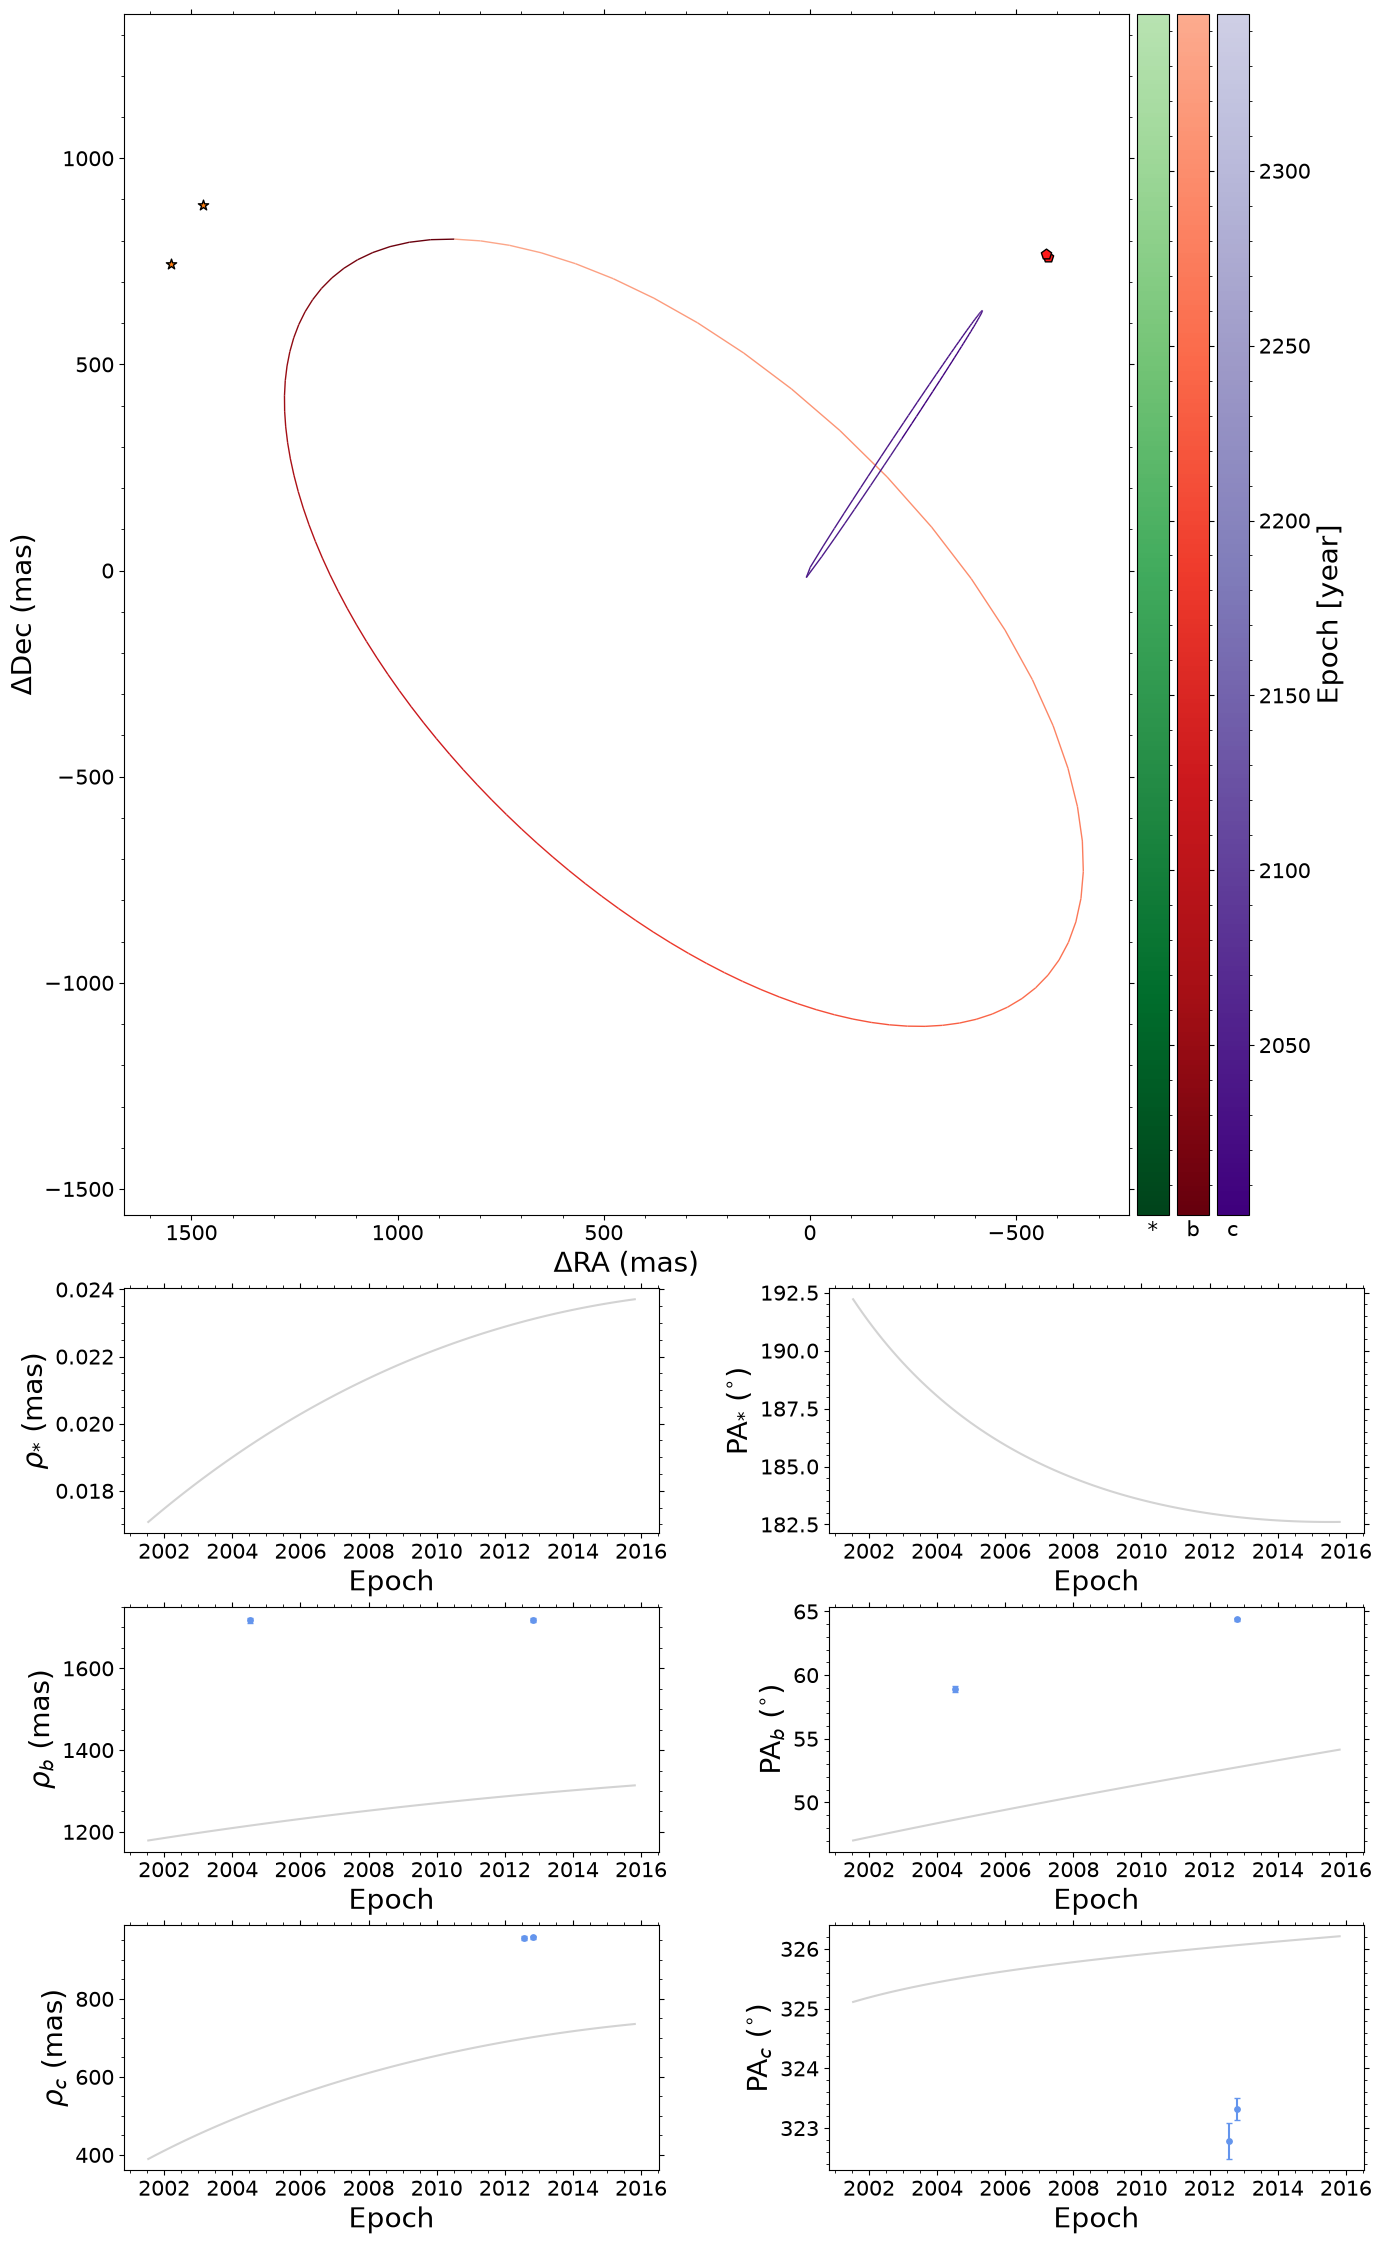

In [22]:
orbit_figure_primary_best = myPlotter2.plot_orbits(
    cmap=cmaps
)  # The primary may be hard to see due to not moving much